In [1]:
import random
from collections import deque

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cpu")

P = 0.025
REPLAY_SIZE = 10000
T_EPI = 50
N_QU = 4
GAMMA = 0.99
N_BATCH = 64
LR = 1e-3
ETA = 0.01
N_EPI = 1200
EPS_MIN = 0.10
EPS_DECAY = 0.995
WARMUP = 256

ACTIONS = ["U", "R", "D", "L"]

MOVE = {
    "U": (-1, 0),
    "R": (0, 1),
    "D": (1, 0),
    "L": (0, -1),
}

PERP = {
    "U": ["L", "R"],
    "R": ["U", "D"],
    "D": ["L", "R"],
    "L": ["U", "D"],
}

ARROW = {
    "U": "↑",
    "R": "→",
    "D": "↓",
    "L": "←",
}

maze = [
    ["E", "Y", "E", "E", "E", "G", "E", "E"],
    ["E", "E", "E", "W", "E", "E", "E", "E"],
    ["E", "R", "W", "W", "W", "W", "Y", "W"],
    ["E", "E", "E", "W", "E", "E", "E", "E"],
    ["E", "Y", "E", "E", "E", "W", "Y", "E"],
    ["W", "W", "W", "R", "E", "W", "E", "E"],
    ["E", "S", "R", "E", "E", "W", "R", "E"],
    ["E", "E", "E", "E", "E", "W", "E", "E"],
]

rows = len(maze)
cols = len(maze[0])

state_list = []
state_of = {}
start_state = None
goal_state = None

for r in range(rows):
    for c in range(cols):
        if maze[r][c] != "W":
            s = len(state_list)
            state_list.append((r, c))
            state_of[(r, c)] = s
            if maze[r][c] == "S":
                start_state = s
            if maze[r][c] == "G":
                goal_state = s

nS = len(state_list)
nA = len(ACTIONS)

start_pool = [s for s in range(nS) if s != goal_state]

print("rows =", rows, "cols =", cols)
print("states =", nS)
print("start state =", start_state, state_list[start_state])
print("goal state =", goal_state, state_list[goal_state])

def reward_value(cell, hit_wall=False):
    r = -1.0
    if hit_wall:
        r += -0.8
    else:
        if cell == "Y":
            r += -5.0
        elif cell == "R":
            r += -10.0
        elif cell == "G":
            r += 100.0
    return r

def state_vec(s):
    r, c = state_list[s]
    x = c / (cols - 1)
    y = r / (rows - 1)
    return np.array([x, y], dtype=np.float32)

def step_env(s, a, rng):
    if s == goal_state:
        return goal_state, 0.0, True

    a0 = ACTIONS[a]
    moves = [(a0, 1.0 - P)]
    for ax in PERP[a0]:
        moves.append((ax, P / 2.0))

    k = rng.choice(len(moves), p=[pr for _, pr in moves])
    move_a = moves[k][0]

    r0, c0 = state_list[s]
    dr, dc = MOVE[move_a]
    r1 = r0 + dr
    c1 = c0 + dc

    if r1 < 0 or r1 >= rows or c1 < 0 or c1 >= cols or maze[r1][c1] == "W":
        s2 = s
        rew = reward_value(maze[r0][c0], hit_wall=True)
    else:
        s2 = state_of[(r1, c1)]
        rew = reward_value(maze[r1][c1], hit_wall=False)

    done = s2 == goal_state
    return s2, rew, done

class ReplayMemory:
    def __init__(self, capacity):
        self.data = deque(maxlen=capacity)

    def push(self, item):
        self.data.append(item)

    def sample(self, n, rng):
        idx = rng.choice(len(self.data), size=n, replace=False)
        batch = [self.data[i] for i in idx]
        s, a, r, s2, d = zip(*batch)
        return (
            np.array(s, dtype=np.float32),
            np.array(a, dtype=np.int64),
            np.array(r, dtype=np.float32),
            np.array(s2, dtype=np.float32),
            np.array(d, dtype=np.float32),
        )

    def __len__(self):
        return len(self.data)

class DQN(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(2, 128)
        self.layer2 = nn.Linear(128, 128)
        self.layer3 = nn.Linear(128, 128)
        self.layer4 = nn.Linear(128, 4)

    def forward(self, x):
        x = F.relu(self.layer1(x))
        x = F.relu(self.layer2(x))
        x = F.relu(self.layer3(x))
        return self.layer4(x)

class DuelingDQN(nn.Module):
    def __init__(self):
        super().__init__()
        self.feature1 = nn.Linear(2, 128)
        self.feature2 = nn.Linear(128, 128)
        self.value1 = nn.Linear(128, 128)
        self.value2 = nn.Linear(128, 1)
        self.adv1 = nn.Linear(128, 128)
        self.adv2 = nn.Linear(128, 4)

    def forward(self, x):
        x = F.relu(self.feature1(x))
        x = F.relu(self.feature2(x))
        v = F.relu(self.value1(x))
        v = self.value2(v)
        a = F.relu(self.adv1(x))
        a = self.adv2(a)
        return v + (a - a.mean(dim=1, keepdim=True))

def eps_value(ep):
    return max(EPS_MIN, EPS_DECAY ** ep)

def moving_avg(x, w=25):
    out = np.zeros(len(x))
    for i in range(len(x)):
        m = min(w, i + 1)
        out[i] = np.mean(x[i - m + 1:i + 1])
    return out

def q_values_on_states(model):
    xs = np.array([state_vec(s) for s in range(nS)], dtype=np.float32)
    with torch.no_grad():
        q = model(torch.tensor(xs, device=DEVICE)).cpu().numpy()
    return q

def greedy_policy(model):
    q = q_values_on_states(model)
    return np.argmax(q, axis=1), np.max(q, axis=1)

def choose_action(model, s, eps, rng):
    if rng.random() < eps:
        return int(rng.integers(nA))
    x = torch.tensor(state_vec(s)).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        q = model(x)[0].cpu().numpy()
    return int(np.argmax(q))

def optimize(model, target_model, memory, opt, rng, double=False):
    s, a, r, s2, d = memory.sample(N_BATCH, rng)

    s = torch.tensor(s, device=DEVICE)
    a = torch.tensor(a, device=DEVICE).unsqueeze(1)
    r = torch.tensor(r, device=DEVICE)
    s2 = torch.tensor(s2, device=DEVICE)
    d = torch.tensor(d, device=DEVICE)

    q = model(s).gather(1, a).squeeze(1)

    with torch.no_grad():
        if double:
            a2 = model(s2).argmax(dim=1, keepdim=True)
            q2 = target_model(s2).gather(1, a2).squeeze(1)
        else:
            q2 = target_model(s2).max(dim=1).values
        z = r + GAMMA * q2 * (1.0 - d)

    loss = F.mse_loss(q, z)
    opt.zero_grad()
    loss.backward()
    opt.step()

    for tp, p in zip(target_model.parameters(), model.parameters()):
        tp.data.copy_(ETA * p.data + (1.0 - ETA) * tp.data)

    return float(loss.item())

def train_one(model_kind="standard", lr=LR, seed=0):
    torch.manual_seed(seed)
    random.seed(seed)
    np.random.seed(seed)
    rng = np.random.default_rng(seed)

    if model_kind == "dueling":
        model = DuelingDQN().to(DEVICE)
        target_model = DuelingDQN().to(DEVICE)
    else:
        model = DQN().to(DEVICE)
        target_model = DQN().to(DEVICE)

    target_model.load_state_dict(model.state_dict())
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    memory = ReplayMemory(REPLAY_SIZE)

    epi_rewards = []
    epi_losses = []
    epi_lengths = []

    step_count = 0

    for ep in range(N_EPI):
        s = int(rng.choice(start_pool))
        eps = eps_value(ep)
        total_reward = 0.0
        total_loss = 0.0
        steps = 0

        for t in range(T_EPI):
            a = choose_action(model, s, eps, rng)
            s2, r, done = step_env(s, a, rng)

            memory.push((state_vec(s), a, r, state_vec(s2), float(done)))

            total_reward += r
            steps += 1
            step_count += 1
            s = s2

            if len(memory) >= WARMUP and step_count % N_QU == 0:
                loss = optimize(
                    model,
                    target_model,
                    memory,
                    opt,
                    rng,
                    double=(model_kind == "double"),
                )
                total_loss += loss

            if done:
                break

        epi_rewards.append(total_reward)
        epi_losses.append(total_loss)
        epi_lengths.append(steps)

    avg_reward = moving_avg(np.array(epi_rewards))
    avg_loss = moving_avg(np.array(epi_losses))
    avg_length = moving_avg(np.array(epi_lengths))

    policy, values = greedy_policy(model)

    return {
        "model": model,
        "policy": policy,
        "values": values,
        "epi_rewards": np.array(epi_rewards),
        "epi_losses": np.array(epi_losses),
        "epi_lengths": np.array(epi_lengths),
        "avg_reward": avg_reward,
        "avg_loss": avg_loss,
        "avg_length": avg_length,
        "lr": lr,
        "kind": model_kind,
    }

def maze_codes():
    code = {"E": 0, "W": 1, "Y": 2, "R": 3, "S": 4, "G": 5}
    return np.array([[code[x] for x in row] for row in maze])

def plot_maze_base(title=""):
    cmap = ListedColormap([
        "#f4f1ea",
        "#000000",
        "#fff200",
        "#ff0000",
        "#1738ff",
        "#00ff11",
    ])
    bg = maze_codes()
    plt.imshow(bg, cmap=cmap, vmin=0, vmax=5)
    plt.xticks(np.arange(cols))
    plt.yticks(np.arange(rows))
    plt.gca().set_xticks(np.arange(-0.5, cols, 1), minor=True)
    plt.gca().set_yticks(np.arange(-0.5, rows, 1), minor=True)
    plt.grid(which="minor", color="gray", linewidth=0.6)
    plt.tick_params(which="minor", bottom=False, left=False)
    plt.xlim(-0.5, cols - 0.5)
    plt.ylim(rows - 0.5, -0.5)
    plt.title(title)

def plot_policy(policy, title):
    plt.figure(figsize=(7, 7))
    plot_maze_base(title)
    for s in range(nS):
        r, c = state_list[s]
        if maze[r][c] not in ["S", "G"]:
            plt.text(c, r, ARROW[ACTIONS[policy[s]]], ha="center", va="center", fontsize=12)
    plt.tight_layout()
    plt.show()

def plot_values(values, title):
    grid = np.full((rows, cols), np.nan)
    for s in range(nS):
        r, c = state_list[s]
        grid[r, c] = values[s]

    plt.figure(figsize=(7, 7))
    plot_maze_base(title)
    masked = np.ma.masked_invalid(grid)
    plt.imshow(masked, cmap="coolwarm", alpha=0.65)
    for s in range(nS):
        r, c = state_list[s]
        plt.text(c, r, f"{values[s]:.1f}", ha="center", va="center", fontsize=8)
    plt.tight_layout()
    plt.show()

def sample_path(policy, seed=0, tries=100):
    for k in range(tries):
        rng = np.random.default_rng(seed + k)
        s = start_state
        path = [s]
        for t in range(T_EPI):
            if s == goal_state:
                return path, True
            a = policy[s]
            s2, r, done = step_env(s, a, rng)
            path.append(s2)
            s = s2
            if done:
                return path, True
        if path[-1] == goal_state:
            return path, True
    return path, False

def plot_path(path, title):
    plt.figure(figsize=(7, 7))
    plot_maze_base(title)
    pts = np.array([state_list[s] for s in path])
    plt.plot(pts[:, 1], pts[:, 0], "k--o", linewidth=1.5, markersize=4)
    plt.tight_layout()
    plt.show()

def print_params():
    print("replay size =", REPLAY_SIZE)
    print("T_epi =", T_EPI)
    print("N_QU =", N_QU)
    print("gamma =", GAMMA)
    print("N_batch =", N_BATCH)
    print("alpha =", LR)
    print("eta =", ETA)
    print("N_epi =", N_EPI)
    print("epsilon_k = max(0.1, 0.995^k)")
    print("state = normalized (x, y) in [0, 1]")

def show_training_plots(res, title):
    x = np.arange(1, N_EPI + 1)

    plt.figure(figsize=(8, 4))
    plt.plot(x, res["avg_reward"])
    plt.xlabel("episode")
    plt.ylabel("Avg Reward")
    plt.title(f"{title}: average reward")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(8, 4))
    plt.plot(x, res["avg_loss"])
    plt.xlabel("episode")
    plt.ylabel("Avg Loss")
    plt.title(f"{title}: average loss")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(8, 4))
    plt.plot(x, res["avg_length"])
    plt.xlabel("episode")
    plt.ylabel("Avg Length")
    plt.title(f"{title}: average episode length")
    plt.tight_layout()
    plt.show()

def summary(res, title):
    path, ok = sample_path(res["policy"], seed=SEED)
    print()
    print(title)
    print("last avg reward =", res["avg_reward"][-1])
    print("last avg loss =", res["avg_loss"][-1])
    print("last avg length =", res["avg_length"][-1])
    print("path found =", ok)
    print("path length =", len(path) - 1)
    return path, ok


rows = 8 cols = 8
states = 50
start state = 37 (6, 1)
goal state = 5 (0, 5)


replay size = 10000
T_epi = 50
N_QU = 4
gamma = 0.99
N_batch = 64
alpha = 0.001
eta = 0.01
N_epi = 1200
epsilon_k = max(0.1, 0.995^k)
state = normalized (x, y) in [0, 1]



Standard DQN
last avg reward = 86.08
last avg loss = 5.146093838214874
last avg length = 7.56
path found = True
path length = 12


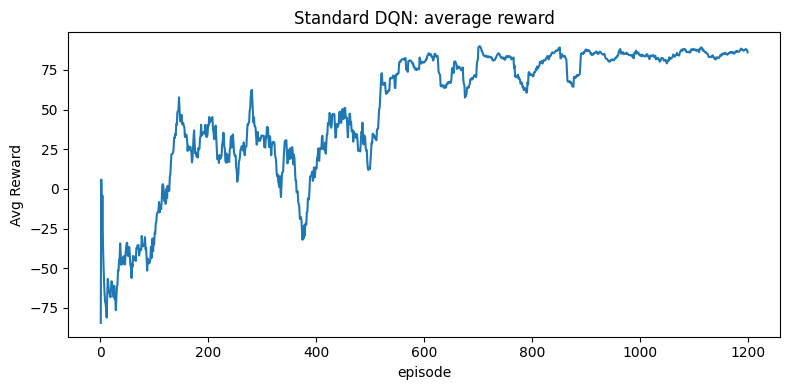

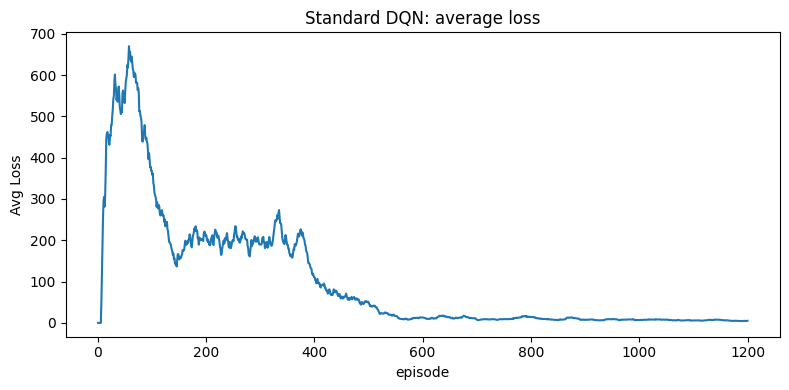

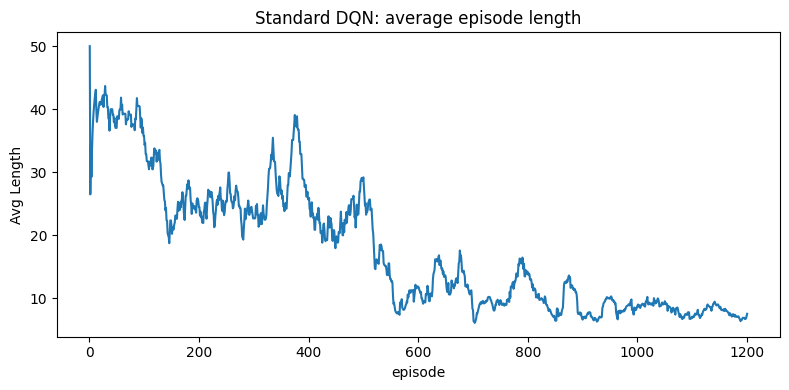

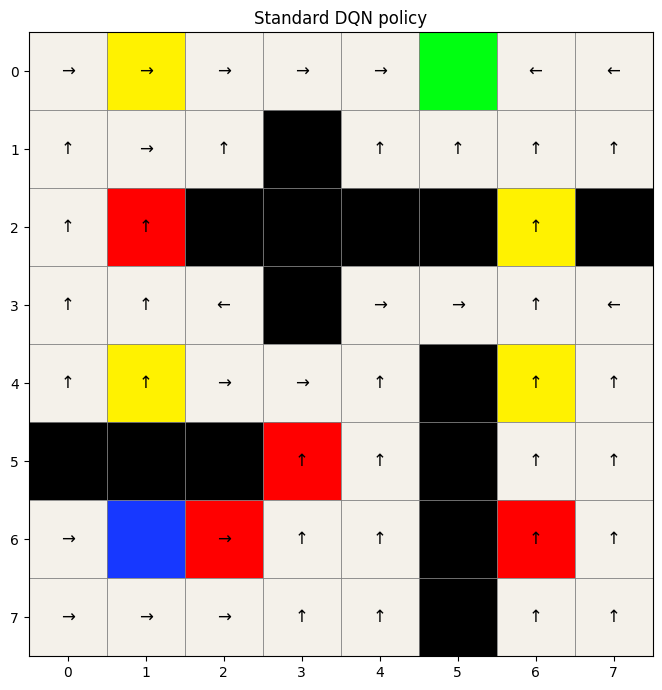

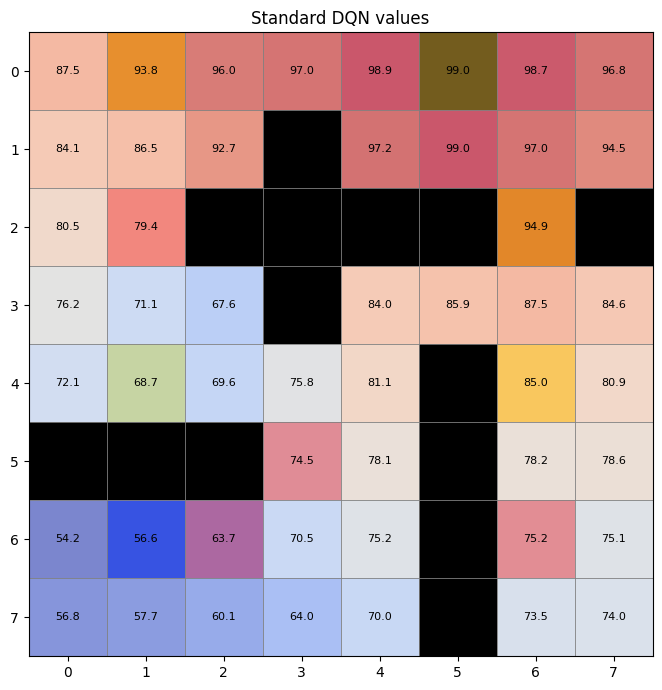

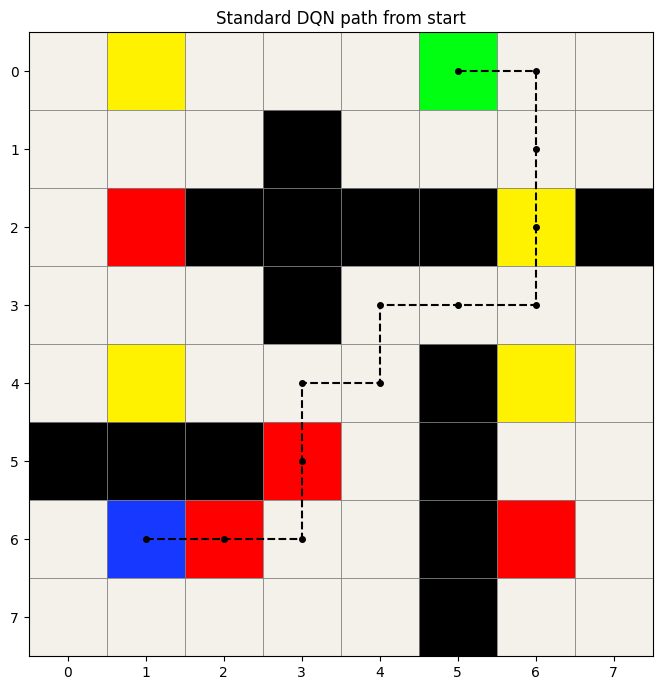

In [2]:
print_params()

standard = train_one("standard", lr=LR, seed=SEED)
path_std, ok_std = summary(standard, "Standard DQN")

show_training_plots(standard, "Standard DQN")
plot_policy(standard["policy"], "Standard DQN policy")
plot_values(standard["values"], "Standard DQN values")
plot_path(path_std, "Standard DQN path from start")



learning rate sweep
small lr = 0.0001 | last avg reward = 17.400000000000023
base  lr = 0.001 | last avg reward = 86.08
large lr = 0.01 | last avg reward = 87.4


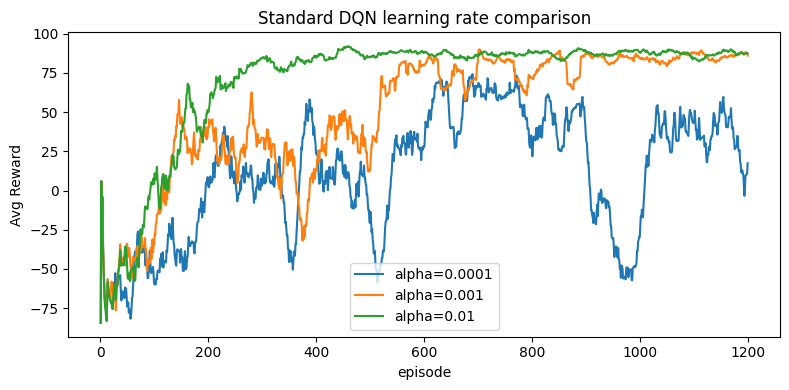

In [3]:
small_lr = train_one("standard", lr=LR / 10.0, seed=SEED)
large_lr = train_one("standard", lr=LR * 10.0, seed=SEED)

print()
print("learning rate sweep")
print("small lr =", LR / 10.0, "| last avg reward =", small_lr["avg_reward"][-1])
print("base  lr =", LR, "| last avg reward =", standard["avg_reward"][-1])
print("large lr =", LR * 10.0, "| last avg reward =", large_lr["avg_reward"][-1])

x = np.arange(1, N_EPI + 1)
plt.figure(figsize=(8, 4))
plt.plot(x, small_lr["avg_reward"], label=f"alpha={LR/10.0:g}")
plt.plot(x, standard["avg_reward"], label=f"alpha={LR:g}")
plt.plot(x, large_lr["avg_reward"], label=f"alpha={LR*10.0:g}")
plt.xlabel("episode")
plt.ylabel("Avg Reward")
plt.title("Standard DQN learning rate comparison")
plt.legend()
plt.tight_layout()
plt.show()



Double DQN
last avg reward = 88.11200000000001
last avg loss = 4.896332352161408
last avg length = 6.84
path found = True
path length = 12


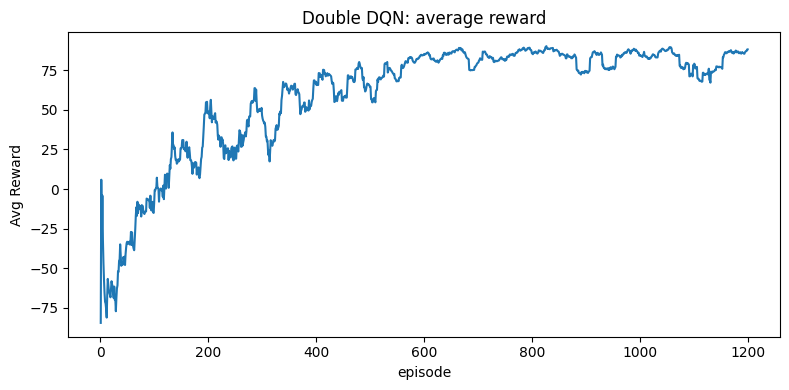

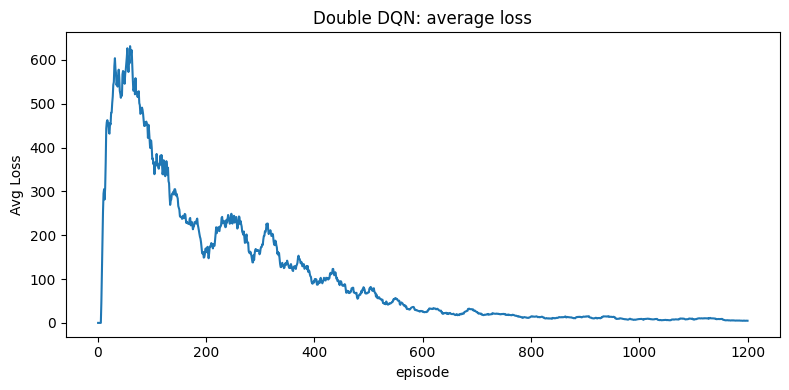

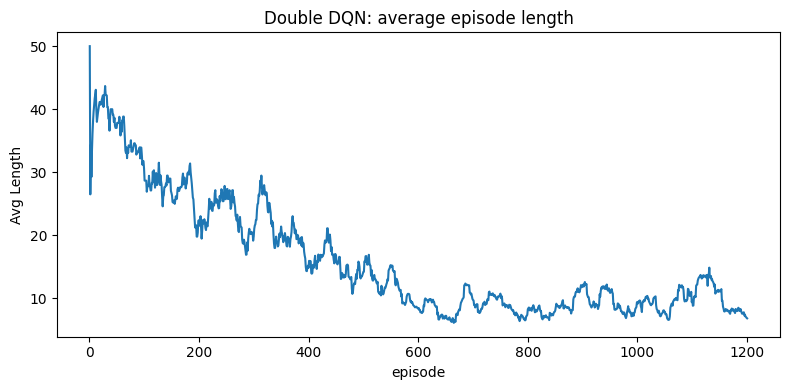

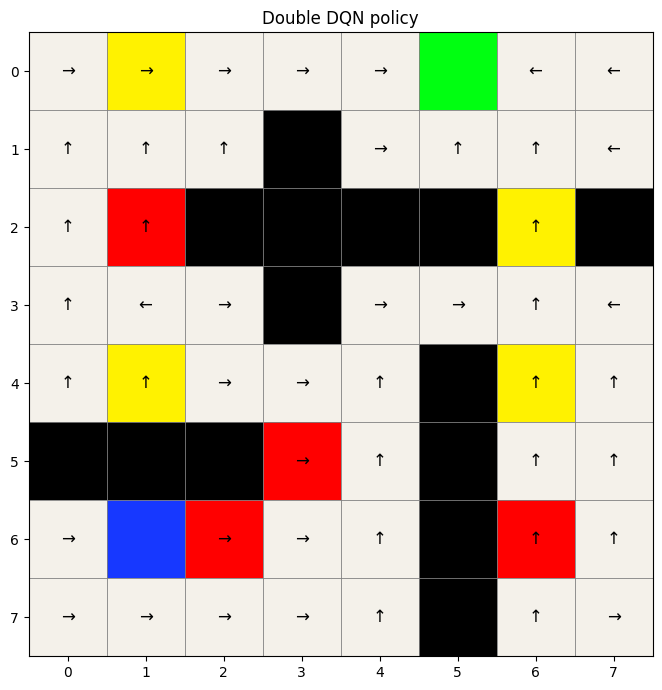

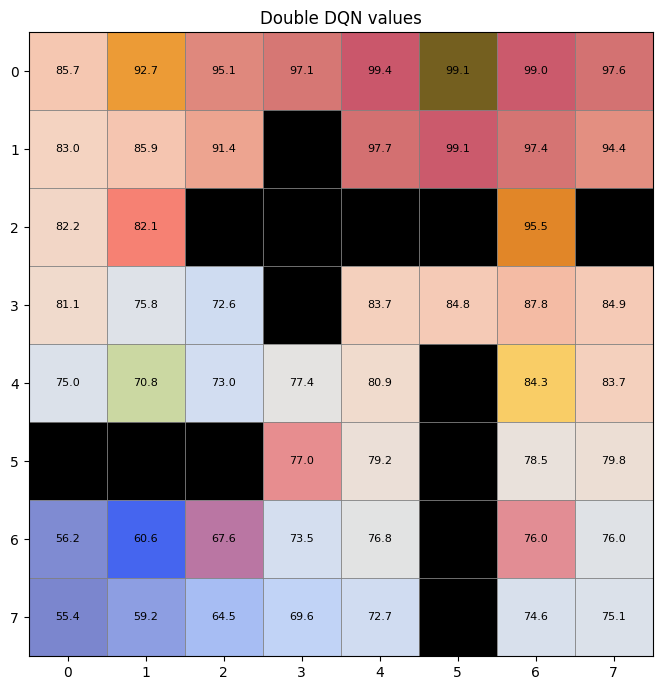

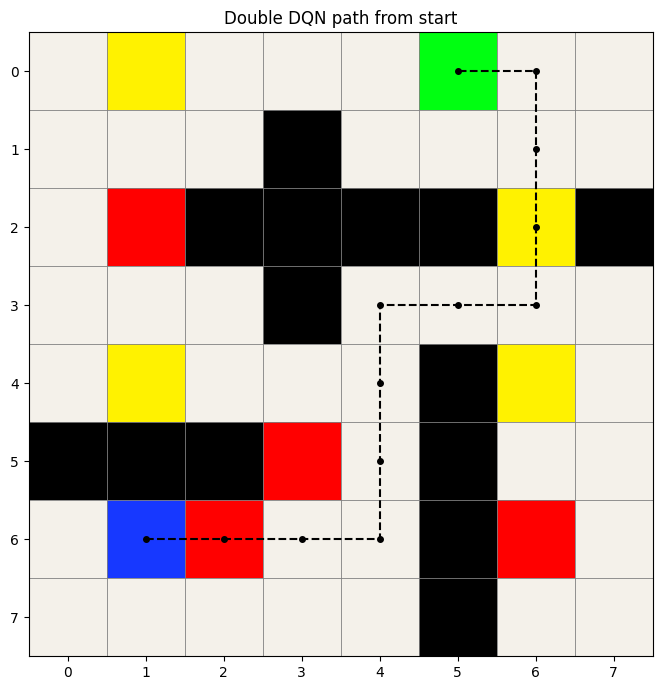


standard vs double
standard last avg reward = 86.08
double   last avg reward = 88.11200000000001
standard last avg length = 7.56
double   last avg length = 6.84


In [4]:
double = train_one("double", lr=LR, seed=SEED)
path_double, ok_double = summary(double, "Double DQN")

show_training_plots(double, "Double DQN")
plot_policy(double["policy"], "Double DQN policy")
plot_values(double["values"], "Double DQN values")
plot_path(path_double, "Double DQN path from start")

print()
print("standard vs double")
print("standard last avg reward =", standard["avg_reward"][-1])
print("double   last avg reward =", double["avg_reward"][-1])
print("standard last avg length =", standard["avg_length"][-1])
print("double   last avg length =", double["avg_length"][-1])



Dueling DQN
last avg reward = 87.624
last avg loss = 3.6085251820087434
last avg length = 7.52
path found = True
path length = 12


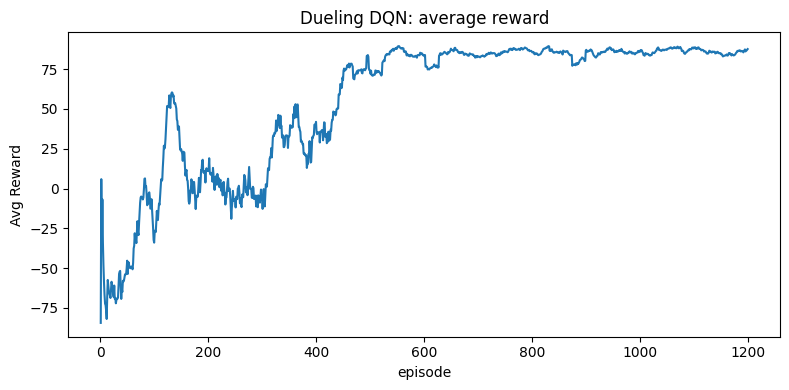

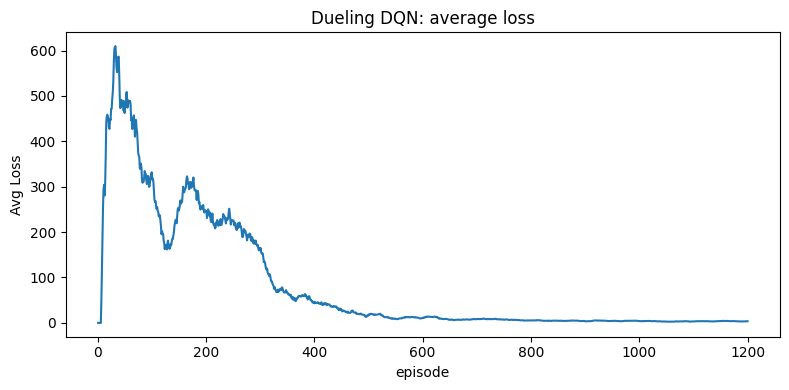

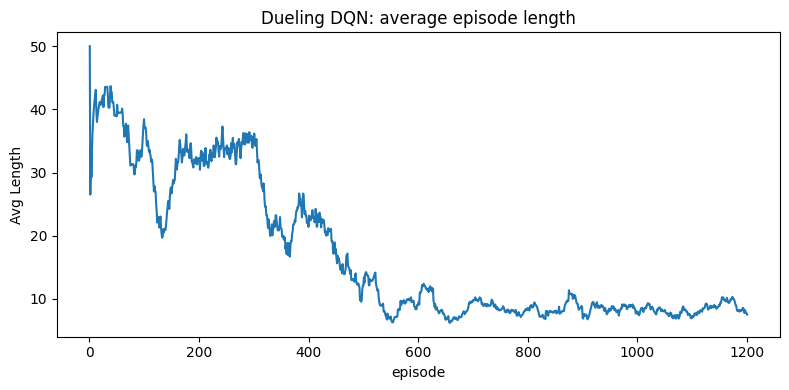

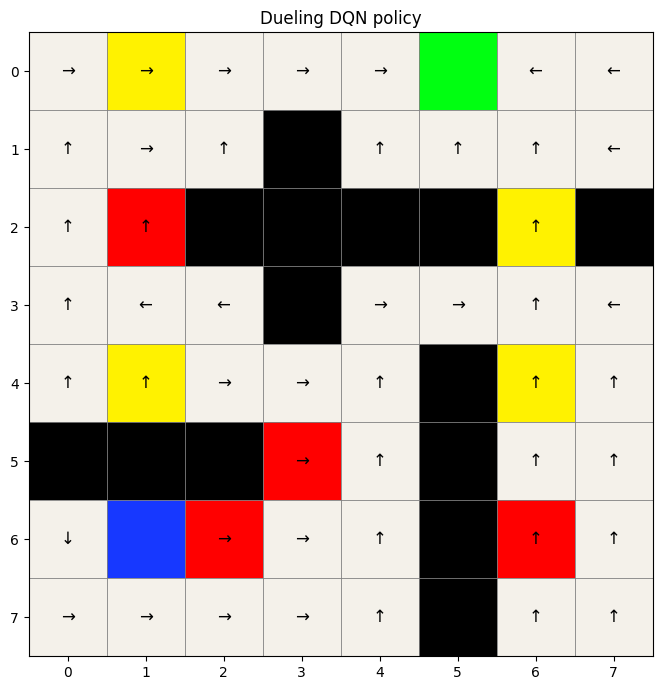

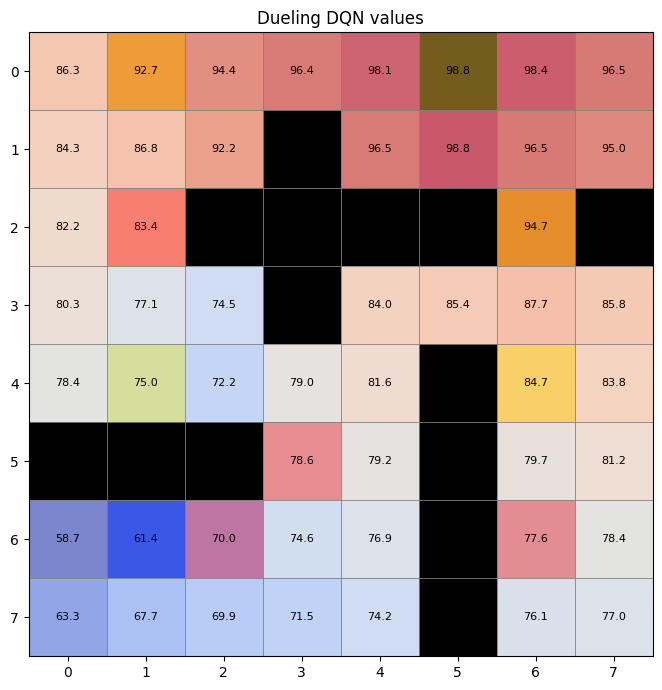

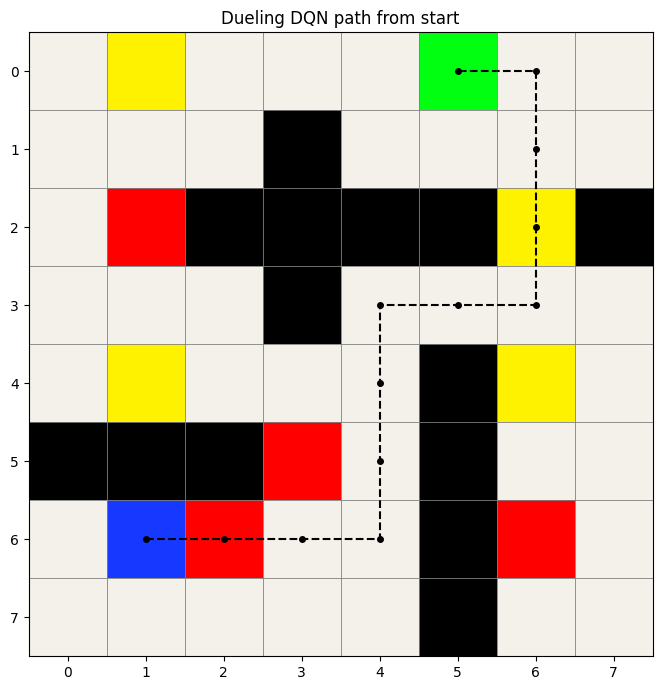


standard vs double vs dueling
standard last avg reward = 86.08
double   last avg reward = 88.11200000000001
dueling  last avg reward = 87.624
standard last avg length = 7.56
double   last avg length = 6.84
dueling  last avg length = 7.52


In [5]:
dueling = train_one("dueling", lr=LR, seed=SEED)
path_dueling, ok_dueling = summary(dueling, "Dueling DQN")

show_training_plots(dueling, "Dueling DQN")
plot_policy(dueling["policy"], "Dueling DQN policy")
plot_values(dueling["values"], "Dueling DQN values")
plot_path(path_dueling, "Dueling DQN path from start")

print()
print("standard vs double vs dueling")
print("standard last avg reward =", standard["avg_reward"][-1])
print("double   last avg reward =", double["avg_reward"][-1])
print("dueling  last avg reward =", dueling["avg_reward"][-1])
print("standard last avg length =", standard["avg_length"][-1])
print("double   last avg length =", double["avg_length"][-1])
print("dueling  last avg length =", dueling["avg_length"][-1])
